# Fuzzy-LSTM Hybrid Market Direction Predictor
### Soft Computing Lab Project — Fuzzy Inference System + LSTM (100 companies, US + India)


## Phase 1 — Environment & Data Engineering

In [ ]:
# 1. Install dependencies
!pip install -q yfinance scikit-fuzzy torch numpy pandas matplotlib scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 31.0 MB/s eta 0:00:00


In [ ]:
# 2. Imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
import skfuzzy as fuzz
from skfuzzy import control as ctrl

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


Using device: cuda


### 100-company universe (60 US + 40 India / NSE)

Indian tickers use the `.NS` suffix (NSE) so `yfinance` resolves them correctly.
Feel free to edit these lists — the rest of the notebook adapts automatically to
however many tickers survive the download.

In [ ]:
US_TICKERS = [
    "AAPL","MSFT","GOOGL","AMZN","NVDA","META","TSLA","BRK-B","JPM","JNJ",
    "V","PG","UNH","HD","MA","DIS","PYPL","BAC","VZ","ADBE",
    "CMCSA","NFLX","KO","NKE","MRK","PFE","T","INTC","CSCO","XOM",
    "CVX","WMT","MCD","ABT","CRM","ORCL","IBM","QCOM","TXN","HON",
    "AMD","COST","PEP","ABBV","TMO","AVGO","ACN","LLY","DHR","NEE",
    "LIN","UNP","PM","RTX","LOW","UPS","SBUX","BA","GE","CAT",
]

INDIA_TICKERS = [
    "RELIANCE.NS","TCS.NS","HDFCBANK.NS","INFY.NS","ICICIBANK.NS",
    "HINDUNILVR.NS","SBIN.NS","BHARTIARTL.NS","KOTAKBANK.NS","ITC.NS",
    "LT.NS","AXISBANK.NS","BAJFINANCE.NS","ASIANPAINT.NS","MARUTI.NS",
    "HCLTECH.NS","SUNPHARMA.NS","TITAN.NS","ULTRACEMCO.NS","WIPRO.NS",
    "NESTLEIND.NS","ONGC.NS","NTPC.NS","POWERGRID.NS","M&M.NS",
    "TATAMOTORS.NS","TATASTEEL.NS","ADANIENT.NS","ADANIPORTS.NS","JSWSTEEL.NS",
    "GRASIM.NS","BAJAJFINSV.NS","HDFCLIFE.NS","SBILIFE.NS","DIVISLAB.NS",
    "DRREDDY.NS","CIPLA.NS","EICHERMOT.NS","HEROMOTOCO.NS","BRITANNIA.NS",
]

TICKERS = US_TICKERS + INDIA_TICKERS
print(f"Universe size: {len(TICKERS)} tickers "
      f"({len(US_TICKERS)} US + {len(INDIA_TICKERS)} India)")

START_DATE = "2015-01-01"
END_DATE = None  # None -> up to the most recent available session
WINDOW = 60      # sliding window length (days)


Universe size: 100 tickers (60 US + 40 India)


### 3. Data extraction (batched download, one HTTP round-trip per chunk)

In [ ]:
def batch_download(tickers, start, end, chunk_size=20):
    """Download OHLCV for many tickers efficiently, in chunks, and return
    a dict {ticker: DataFrame[Open, High, Low, Close, Volume]}."""
    frames = {}
    for i in range(0, len(tickers), chunk_size):
        chunk = tickers[i:i + chunk_size]
        print(f"Downloading {i + 1}-{i + len(chunk)} / {len(tickers)} ...")
        raw = yf.download(
            tickers=chunk, start=start, end=end, group_by="ticker",
            auto_adjust=True, threads=True, progress=False,
        )
        for t in chunk:
            try:
                if len(chunk) == 1:
                    df = raw.copy()
                else:
                    df = raw[t].copy()
                df = df[["Open", "High", "Low", "Close", "Volume"]].dropna(how="all")
                if len(df) > (WINDOW + 30):   # need enough history to be usable
                    frames[t] = df
                else:
                    print(f"  skipping {t}: insufficient history ({len(df)} rows)")
            except Exception as e:
                print(f"  skipping {t}: {e}")
    return frames

raw_data = batch_download(TICKERS, START_DATE, END_DATE)
print(f"\nSuccessfully downloaded {len(raw_data)} / {len(TICKERS)} tickers.")


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['TATAMOTORS.NS']: YFTzMissingError('possibly delisted; no timezone found')


  skipping TATAMOTORS.NS: insufficient history (0 rows)

Successfully downloaded 99 / 100 tickers.


### 4. Feature engineering — `return_1d`, `volatility_14d`, `target_direction`

In [ ]:
FEATURE_COLS = ["Open", "High", "Low", "Close", "Volume", "return_1d", "volatility_14d"]
TARGET_COL = "target_direction"

def engineer_features(df):
    out = df.copy()
    out["return_1d"] = out["Close"].pct_change()
    out["volatility_14d"] = out["return_1d"].rolling(14).std()
    out["target_direction"] = (out["Close"].shift(-1) > out["Close"]).astype(int)
    out = out.dropna(subset=["return_1d", "volatility_14d"]).copy()
    out = out.iloc[:-1]  # last row's target is undefined (no "tomorrow")
    return out[FEATURE_COLS + [TARGET_COL]]

engineered = {}
for t, df in raw_data.items():
    feat_df = engineer_features(df)
    if len(feat_df) > (WINDOW + 20):
        engineered[t] = feat_df

print(f"Tickers with usable engineered features: {len(engineered)}")
sample_ticker = next(iter(engineered))
engineered[sample_ticker].head()


Tickers with usable engineered features: 99


Price,Open,High,Low,Close,Volume,return_1d,volatility_14d,target_direction
Date,,,,,,,,
2015-01-23,24.828394,25.148973,24.658154,24.978735,185859200,0.005160,0.020192,1
2015-01-26,25.146766,25.283842,24.938942,25.005268,222460000,0.001062,0.018183,0
2015-01-27,24.854928,24.868194,24.105433,24.129753,382274800,-0.035013,0.021051,1
2015-01-28,26.006804,26.115139,25.493876,25.493876,585908400,0.056533,0.025497,1
2015-01-29,25.717174,26.351702,25.549145,26.287586,337745600,0.031133,0.024831,0


### 5 & 6. Scaling + sliding-window sequencing (time-based split, per ticker)


In [ ]:
def make_windows(feature_arr, target_arr, window):
    X, y = [], []
    for i in range(window, len(feature_arr)):
        X.append(feature_arr[i - window:i])
        y.append(target_arr[i - 1])   # target aligned with the last day in the window
    if not X:
        return np.empty((0, window, feature_arr.shape[1])), np.empty((0,))
    return np.array(X), np.array(y)

def split_scale_window(df, window=WINDOW, train_frac=0.8, val_frac=0.1):
    n = len(df)
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)

    train_df = df.iloc[:n_train]
    val_df = df.iloc[n_train:n_train + n_val]
    test_df = df.iloc[n_train + n_val:]

    scaler = MinMaxScaler()
    scaler.fit(train_df[FEATURE_COLS].values)

    splits = {}
    for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
        if len(part) <= window:
            splits[name] = (np.empty((0, window, len(FEATURE_COLS))), np.empty((0,)))
            continue
        scaled = scaler.transform(part[FEATURE_COLS].values)
        X, y = make_windows(scaled, part[TARGET_COL].values, window)
        splits[name] = (X, y)
    return splits

all_splits = {"train": [], "val": [], "test": []}
kept_tickers = []
for t, df in engineered.items():
    s = split_scale_window(df)
    if len(s["train"][0]) == 0 or len(s["test"][0]) == 0:
        continue
    kept_tickers.append(t)
    for name in ["train", "val", "test"]:
        X, y = s[name]
        if len(X):
            all_splits[name].append((X, y))

print(f"Tickers contributing usable windows: {len(kept_tickers)}")

X_train = np.concatenate([x for x, _ in all_splits["train"]], axis=0)
y_train = np.concatenate([y for _, y in all_splits["train"]], axis=0)
X_val   = np.concatenate([x for x, _ in all_splits["val"]], axis=0)
y_val   = np.concatenate([y for _, y in all_splits["val"]], axis=0)
X_test  = np.concatenate([x for x, _ in all_splits["test"]], axis=0)
y_test  = np.concatenate([y for _, y in all_splits["test"]], axis=0)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

VOL_COL_IDX = FEATURE_COLS.index("volatility_14d")  # needed later for the fuzzy controller


Tickers contributing usable windows: 99
Train: (222980, 60, 7) (222980,)
Val:   (22621, 60, 7) (22621,)
Test:  (22760, 60, 7) (22760,)


### 6b. Calibrate the fuzzy controller's thresholds to the REAL data distribution


In [ ]:
# Use the LAST day of each window (the most "current" volatility reading for that
# sample) — the same statistic train_model() will feed the controller per batch.
train_vol_last = X_train[:, -1, VOL_COL_IDX]
VOL_P33, VOL_P50, VOL_P66, VOL_P90 = np.percentile(train_vol_last, [33, 50, 66, 90])
print(f"Volatility percentiles -> p33={VOL_P33:.4f}  p50={VOL_P50:.4f}  "
      f"p66={VOL_P66:.4f}  p90={VOL_P90:.4f}")


Volatility percentiles -> p33=0.1020  p50=0.1364  p66=0.1778  p90=0.3051


In [ ]:
# Shuffle only the training set (rows are independent 60-day windows already;
# shuffling across tickers/time just improves batch diversity for SGD)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_train))
X_train, y_train = X_train[perm], y_train[perm]

train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                          torch.tensor(y_train, dtype=torch.float32))
val_ds   = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                          torch.tensor(y_val, dtype=torch.float32))
test_ds  = TensorDataset(torch.tensor(X_test, dtype=torch.float32),
                          torch.tensor(y_test, dtype=torch.float32))

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)


## Phase 2 — Fuzzy Logic Controller (Soft Computing layer)

- **Input (antecedent):** batch-average, **last-day** `volatility_14d` (already Min-Max
  scaled to [0, 1]).
- **Output (consequent):** learning rate for the optimizer, ranged `[0.0001, 0.01]`.
- **Rule base:**
  1. IF Volatility is **High** THEN Learning Rate is **Lower**
  2. IF Volatility is **Medium** THEN Learning Rate is **Medium**
  3. IF Volatility is **Low** THEN Learning Rate is **Higher**

Set boundaries come from `VOL_P33 / VOL_P50 / VOL_P66` computed above, so the sets are
calibrated to this dataset rather than an assumed uniform spread.


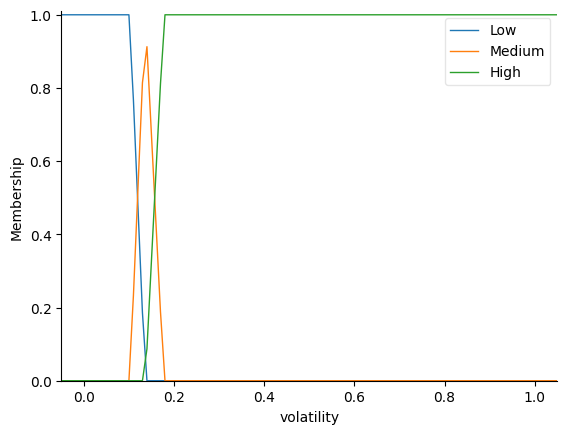

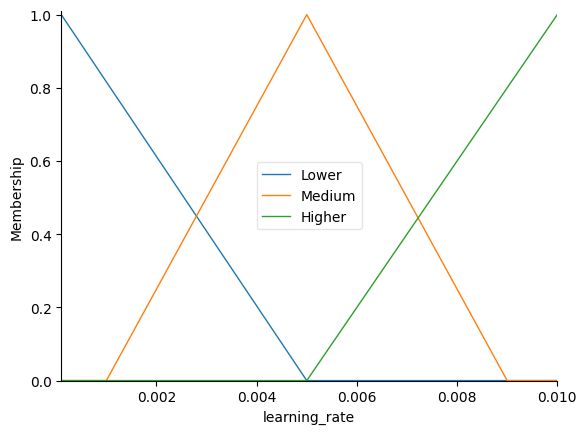

In [ ]:
# 1. Universes — padded slightly beyond [0, 1] so the true extremes (0.0 and 1.0)
# never sit exactly on a membership-function endpoint (which would give zero
# membership everywhere and crash defuzzification with a KeyError).
volatility_universe = np.linspace(-0.05, 1.05, 111)
lr_universe = np.linspace(0.0001, 0.01, 100)

volatility = ctrl.Antecedent(volatility_universe, "volatility")
learning_rate = ctrl.Consequent(lr_universe, "learning_rate")

# 2. Membership functions, calibrated to the empirical percentiles of THIS dataset.
# Low/High use trapmf with a flat "shoulder" so they stay at full membership all the
# way out to the ends of the universe instead of tapering back to zero at 0.0 / 1.0.
volatility["Low"]    = fuzz.trapmf(volatility.universe, [-0.05, -0.05, VOL_P33, VOL_P50])
volatility["Medium"] = fuzz.trimf(volatility.universe,  [VOL_P33, VOL_P50, VOL_P66])
volatility["High"]   = fuzz.trapmf(volatility.universe, [VOL_P50, VOL_P66, 1.05, 1.05])

learning_rate["Lower"]  = fuzz.trimf(learning_rate.universe, [0.0001, 0.0001, 0.005])
learning_rate["Medium"] = fuzz.trimf(learning_rate.universe, [0.001, 0.005, 0.009])
learning_rate["Higher"] = fuzz.trimf(learning_rate.universe, [0.005, 0.01, 0.01])

# (optional) visualize the membership functions
volatility.view()
learning_rate.view()
plt.show()


In [ ]:
# 3. Rule base
rule1 = ctrl.Rule(volatility["High"],   learning_rate["Lower"])
rule2 = ctrl.Rule(volatility["Medium"], learning_rate["Medium"])
rule3 = ctrl.Rule(volatility["Low"],    learning_rate["Higher"])

lr_ctrl_system = ctrl.ControlSystem([rule1, rule2, rule3])

def new_fuzzy_simulator():
    """scikit-fuzzy simulations are stateful; build a fresh one whenever
    you want to query it (cheap) to avoid stale-cache issues across epochs."""
    return ctrl.ControlSystemSimulation(lr_ctrl_system)

def fuzzy_lr(volatility_value, sim=None, default_lr=1e-3):
    """Map a crisp, already-scaled [0,1] volatility value to a crisp learning rate.
    Defensive: if defuzzification ever has no membership to work with (e.g. a NaN
    or an out-of-range edge case slips through), fall back to default_lr instead
    of crashing the training loop."""
    sim = sim or new_fuzzy_simulator()
    v = float(np.clip(volatility_value, 0.0, 1.0))
    sim.input["volatility"] = v
    try:
        sim.compute()
        return float(sim.output["learning_rate"])
    except (KeyError, ValueError):
        return default_lr

# quick sanity check across the volatility range
for v in [0.0, 0.25, 0.5, 0.75, 1.0]:
    print(f"volatility={v:.2f}  ->  fuzzy_lr={fuzzy_lr(v):.5f}")


volatility=0.00  ->  fuzzy_lr=0.00833
volatility=0.25  ->  fuzzy_lr=0.00173
volatility=0.50  ->  fuzzy_lr=0.00173
volatility=0.75  ->  fuzzy_lr=0.00173
volatility=1.00  ->  fuzzy_lr=0.00173


## Phase 3 — Neural Predictor (Deep Learning layer)

In [ ]:
class DirectionLSTM(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]            # final layer's final hidden state
        logit = self.fc(last_hidden)
        return self.sigmoid(logit).squeeze(-1)

N_FEATURES = len(FEATURE_COLS)
print("Model input feature count:", N_FEATURES)


Model input feature count: 7


## Phase 4 — Hybrid Training Loop (Integration)

`train_model(..., use_fuzzy=True)` re-computes the optimizer's learning rate every
batch from that batch's **last-day** (scaled) `volatility_14d` — matching the statistic
the fuzzy sets were calibrated on. `use_fuzzy=False` trains the identical architecture
with one fixed learning rate — the academic baseline. Gradient clipping is included so
the now-genuinely-varying learning rate (which can swing higher than before on calm
batches) doesn't destabilize training.

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    correct = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            preds = model(xb)
            loss = criterion(preds, yb)
            total_loss += loss.item() * len(yb)
            correct += ((preds > 0.5).float() == yb).sum().item()
            n += len(yb)
    return total_loss / max(n, 1), correct / max(n, 1)


def train_model(model, train_loader, val_loader, epochs=15,
                 use_fuzzy=True, fixed_lr=1e-3, vol_col_idx=VOL_COL_IDX,
                 grad_clip_norm=1.0):
    model.to(DEVICE)
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=fixed_lr)
    sim = new_fuzzy_simulator() if use_fuzzy else None

    history = {"train_loss": [], "val_loss": [], "val_acc": [], "lr": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, n_seen = 0.0, 0
        epoch_lrs = []

        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            if use_fuzzy:
                # last day per sample, averaged across the batch -- matches the
                # statistic VOL_P33/P50/P66 were calibrated on
                batch_vol = xb[:, -1, vol_col_idx].mean().item()
                lr = fuzzy_lr(batch_vol, sim=sim)
                for pg in optimizer.param_groups:
                    pg["lr"] = lr
                epoch_lrs.append(lr)
            else:
                epoch_lrs.append(fixed_lr)

            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip_norm)
            optimizer.step()

            running_loss += loss.item() * len(yb)
            n_seen += len(yb)

        train_loss = running_loss / max(n_seen, 1)
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(np.mean(epoch_lrs))

        tag = "Fuzzy-LSTM" if use_fuzzy else "Baseline-LSTM"
        print(f"[{tag}] epoch {epoch:02d}/{epochs} | "
              f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
              f"val_acc={val_acc:.4f} | avg_lr={history['lr'][-1]:.5f}")

    return model, history


In [ ]:
EPOCHS = 15

fuzzy_model = DirectionLSTM(N_FEATURES)
fuzzy_model, fuzzy_history = train_model(
    fuzzy_model, train_loader, val_loader, epochs=EPOCHS, use_fuzzy=True,
)


[Fuzzy-LSTM] epoch 01/15 | train_loss=0.6925 | val_loss=0.6926 | val_acc=0.5179 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 02/15 | train_loss=0.6923 | val_loss=0.6926 | val_acc=0.5179 | avg_lr=0.00326
[Fuzzy-LSTM] epoch 03/15 | train_loss=0.6923 | val_loss=0.6933 | val_acc=0.5055 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 04/15 | train_loss=0.6922 | val_loss=0.6927 | val_acc=0.5139 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 05/15 | train_loss=0.6921 | val_loss=0.6944 | val_acc=0.5036 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 06/15 | train_loss=0.6916 | val_loss=0.6939 | val_acc=0.5061 | avg_lr=0.00326
[Fuzzy-LSTM] epoch 07/15 | train_loss=0.6914 | val_loss=0.6942 | val_acc=0.5071 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 08/15 | train_loss=0.6909 | val_loss=0.6963 | val_acc=0.4940 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 09/15 | train_loss=0.6910 | val_loss=0.6964 | val_acc=0.5020 | avg_lr=0.00326
[Fuzzy-LSTM] epoch 10/15 | train_loss=0.6908 | val_loss=0.6966 | val_acc=0.5052 | avg_lr=0.00327
[Fuzzy-LSTM] epoch 11/15 | tra

### Phase 5 (part 1) — Train the fixed-learning-rate baseline

In [ ]:
baseline_model = DirectionLSTM(N_FEATURES)
baseline_model, baseline_history = train_model(
    baseline_model, train_loader, val_loader, epochs=EPOCHS, use_fuzzy=False, fixed_lr=1e-3,
)


[Baseline-LSTM] epoch 01/15 | train_loss=0.6924 | val_loss=0.6938 | val_acc=0.4941 | avg_lr=0.00100
[Baseline-LSTM] epoch 02/15 | train_loss=0.6924 | val_loss=0.6931 | val_acc=0.5060 | avg_lr=0.00100
[Baseline-LSTM] epoch 03/15 | train_loss=0.6923 | val_loss=0.6948 | val_acc=0.4885 | avg_lr=0.00100
[Baseline-LSTM] epoch 04/15 | train_loss=0.6923 | val_loss=0.6927 | val_acc=0.5109 | avg_lr=0.00100
[Baseline-LSTM] epoch 05/15 | train_loss=0.6922 | val_loss=0.6927 | val_acc=0.5116 | avg_lr=0.00100
[Baseline-LSTM] epoch 06/15 | train_loss=0.6919 | val_loss=0.6965 | val_acc=0.4879 | avg_lr=0.00100
[Baseline-LSTM] epoch 07/15 | train_loss=0.6916 | val_loss=0.6988 | val_acc=0.4904 | avg_lr=0.00100
[Baseline-LSTM] epoch 08/15 | train_loss=0.6915 | val_loss=0.6939 | val_acc=0.5080 | avg_lr=0.00100
[Baseline-LSTM] epoch 09/15 | train_loss=0.6914 | val_loss=0.6932 | val_acc=0.5072 | avg_lr=0.00100
[Baseline-LSTM] epoch 10/15 | train_loss=0.6912 | val_loss=0.6932 | val_acc=0.5067 | avg_lr=0.00100


## Phase 5 — Evaluation & Benchmarking

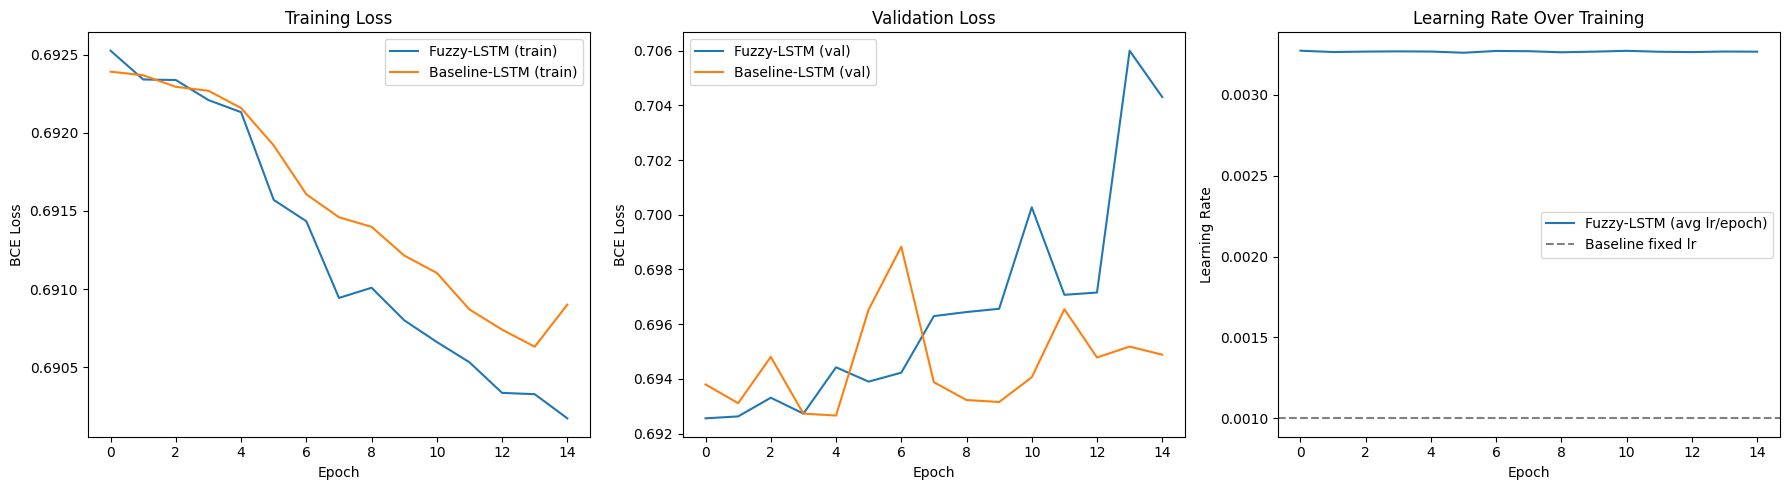

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(fuzzy_history["train_loss"], label="Fuzzy-LSTM (train)")
axes[0].plot(baseline_history["train_loss"], label="Baseline-LSTM (train)")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend()

axes[1].plot(fuzzy_history["val_loss"], label="Fuzzy-LSTM (val)")
axes[1].plot(baseline_history["val_loss"], label="Baseline-LSTM (val)")
axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("BCE Loss"); axes[1].legend()

axes[2].plot(fuzzy_history["lr"], label="Fuzzy-LSTM (avg lr/epoch)")
axes[2].axhline(1e-3, linestyle="--", color="gray", label="Baseline fixed lr")
axes[2].set_title("Learning Rate Over Training")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate"); axes[2].legend()

plt.tight_layout()
plt.show()


In [ ]:
def directional_accuracy(model, loader):
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            preds = (model(xb) > 0.5).float()
            correct += (preds == yb).sum().item()
            n += len(yb)
    return correct / max(n, 1)

fuzzy_test_acc = directional_accuracy(fuzzy_model, test_loader)
baseline_test_acc = directional_accuracy(baseline_model, test_loader)

print(f"Out-of-sample directional accuracy — Fuzzy-LSTM:    {fuzzy_test_acc:.4f}")
print(f"Out-of-sample directional accuracy — Baseline-LSTM: {baseline_test_acc:.4f}")

results = pd.DataFrame({
    "Model": ["Fuzzy-LSTM", "Baseline-LSTM"],
    "Final Train Loss": [fuzzy_history["train_loss"][-1], baseline_history["train_loss"][-1]],
    "Final Val Loss": [fuzzy_history["val_loss"][-1], baseline_history["val_loss"][-1]],
    "Val Loss Std (stability)": [np.std(fuzzy_history["val_loss"]), np.std(baseline_history["val_loss"])],
    "Test Directional Accuracy": [fuzzy_test_acc, baseline_test_acc],
})
results


Out-of-sample directional accuracy — Fuzzy-LSTM:    0.4997
Out-of-sample directional accuracy — Baseline-LSTM: 0.4990


,Model,Final Train Loss,Final Val Loss,Val Loss Std (stability),Test Directional Accuracy
0,Fuzzy-LSTM,0.690173,0.704306,0.003978,0.499692
1,Baseline-LSTM,0.690900,0.694884,0.001650,0.499033
